In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [9]:
df = pd.read_csv(r"C:\Users\milus\Downloads\archive (2)\CAR DETAILS FROM CAR DEKHO.csv")
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [11]:
print("Shape:", df.shape)
print("\nNull values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nFuel values:", df["fuel"].unique())
print("Transmission values:", df["transmission"].unique())

Shape: (4340, 8)

Null values:
 name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate rows: 763

Fuel values: ['Petrol' 'Diesel' 'CNG' 'LPG' 'Electric']
Transmission values: ['Manual' 'Automatic']


In [13]:
# Standardise column names
df.columns = df.columns.str.strip().str.lower()

# Remove duplicates and null values
rows_before = df.shape[0]
df = df.drop_duplicates().dropna().reset_index(drop=True)
print(f"Rows before: {rows_before} | after cleaning: {df.shape[0]}")

# Fix inconsistent text (e.g. "Petrol" vs "petrol ")
for col in ["name", "fuel", "seller_type", "transmission", "owner"]:
    df[col] = df[col].str.strip().str.title()

print("\nFuel types:", df["fuel"].unique())

Rows before: 4340 | after cleaning: 3577

Fuel types: ['Petrol' 'Diesel' 'Cng' 'Lpg' 'Electric']


In [15]:
# Car age from the year column
current_year = datetime.now().year
df["car_age"] = current_year - df["year"]

# Brand is the first word of the car name
df["brand"] = df["name"].str.split().str[0]

df[["name", "brand", "year", "car_age"]].head()

,name,brand,year,car_age
0,Maruti 800 Ac,Maruti,2007,19
1,Maruti Wagon R Lxi Minor,Maruti,2007,19
2,Hyundai Verna 1.6 Sx,Hyundai,2012,14
3,Datsun Redigo T Option,Datsun,2017,9
4,Honda Amaze Vx I-Dtec,Honda,2014,12


In [17]:
print("Number of brands:", df["brand"].nunique())
df["brand"].value_counts().head(10)

Number of brands: 29


brand
Maruti        1072
Hyundai        637
Mahindra       328
Tata           308
Ford           220
Honda          216
Toyota         170
Chevrolet      151
Renault        110
Volkswagen      93
Name: count, dtype: int64

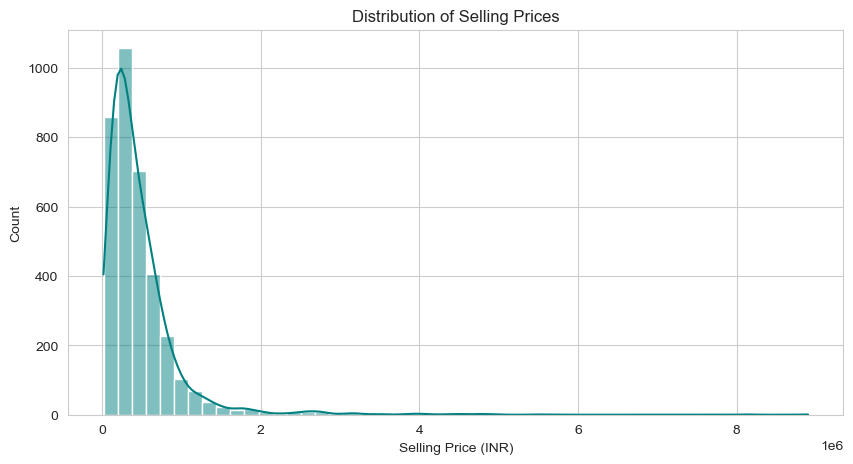

In [19]:
plt.figure(figsize=(10, 5))
sns.histplot(df["selling_price"], bins=50, kde=True, color="teal")
plt.title("Distribution of Selling Prices")
plt.xlabel("Selling Price (INR)")
plt.show()

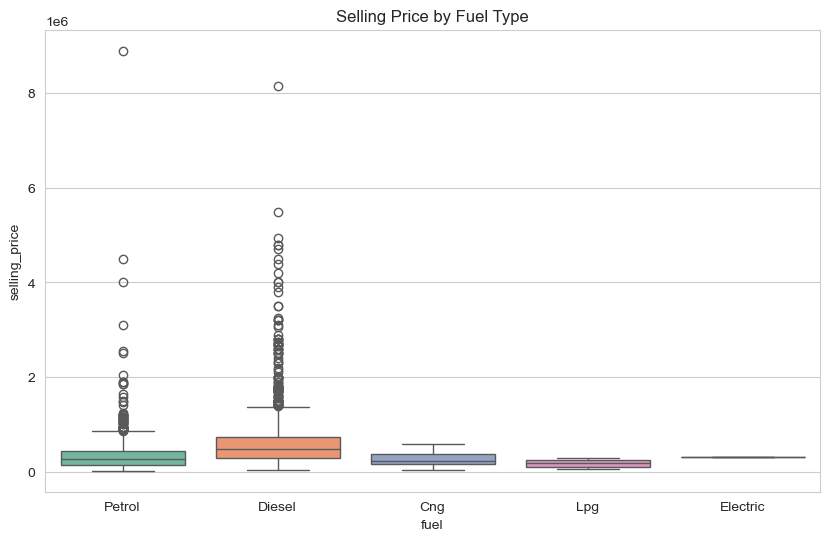

In [21]:
plt.figure(figsize=(10, 6))
sns.boxplot(x="fuel", y="selling_price", data=df, palette="Set2")
plt.title("Selling Price by Fuel Type")
plt.show()

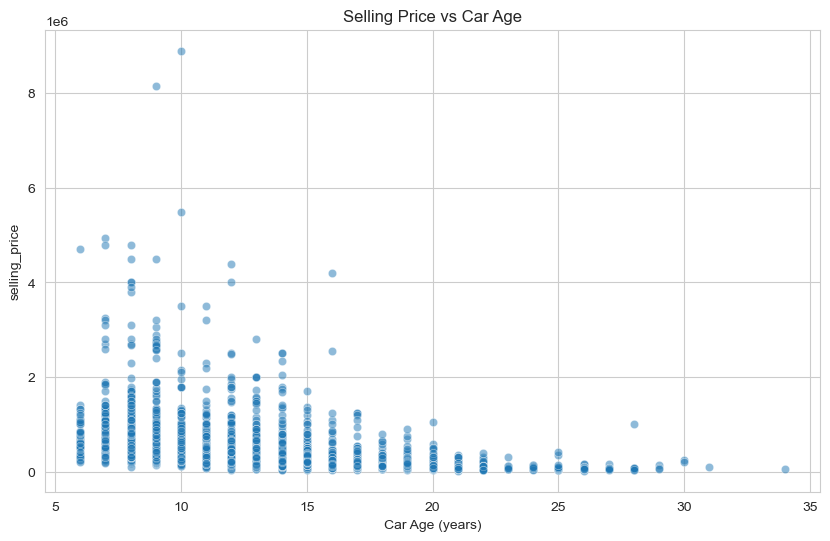

In [23]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x="car_age", y="selling_price", data=df, alpha=0.5)
plt.title("Selling Price vs Car Age")
plt.xlabel("Car Age (years)")
plt.show()

In [25]:
# Drop columns not needed for modelling
data = df.drop(columns=["name", "year"])

# One-hot encode categorical columns
data = pd.get_dummies(
    data, columns=["brand", "fuel", "seller_type", "transmission", "owner"], drop_first=True
)

print("Shape after encoding:", data.shape)
data.head()

Shape after encoding: (3577, 42)


,selling_price,km_driven,car_age,brand_Audi,brand_Bmw,brand_Chevrolet,brand_Daewoo,brand_Datsun,brand_Fiat,brand_Force,...,fuel_Electric,fuel_Lpg,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,60000,70000,19,False,False,False,False,False,False,False,...,False,False,True,True,False,True,False,False,False,False
1,135000,50000,19,False,False,False,False,False,False,False,...,False,False,True,True,False,True,False,False,False,False
2,600000,100000,14,False,False,False,False,False,False,False,...,False,False,False,True,False,True,False,False,False,False
3,250000,46000,9,False,False,False,False,True,False,False,...,False,False,True,True,False,True,False,False,False,False
4,450000,141000,12,False,False,False,False,False,False,False,...,False,False,False,True,False,True,False,True,False,False


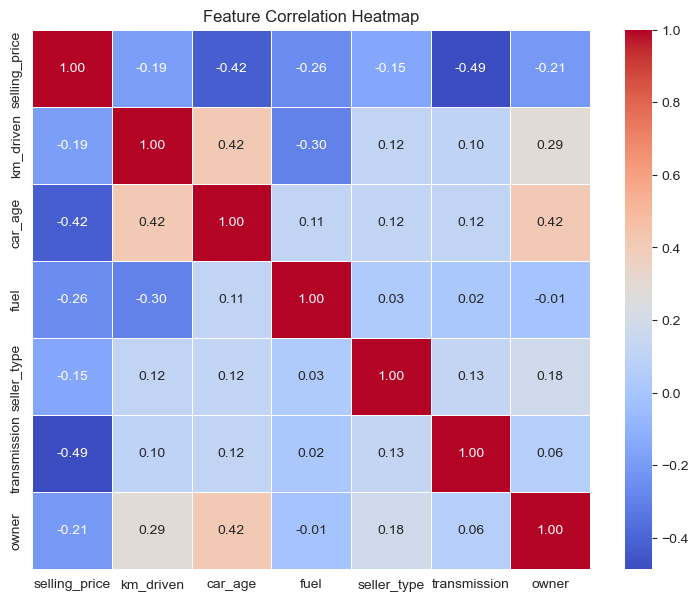

In [27]:
# Numeric version of the categorical columns, for a readable heatmap
heat = df[["selling_price", "km_driven", "car_age"]].copy()
for col in ["fuel", "seller_type", "transmission", "owner"]:
    heat[col] = df[col].astype("category").cat.codes

plt.figure(figsize=(9, 7))
sns.heatmap(heat.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

In [29]:
X = data.drop(columns="selling_price")
y = data["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (2861, 41) | Test: (716, 41)


In [31]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
results_df.round(3)

,Model,MAE,RMSE,R2
0,Random Forest,158857.754,365604.612,0.585
1,Gradient Boosting,157879.641,377658.663,0.557
2,Linear Regression,180194.987,385606.086,0.538


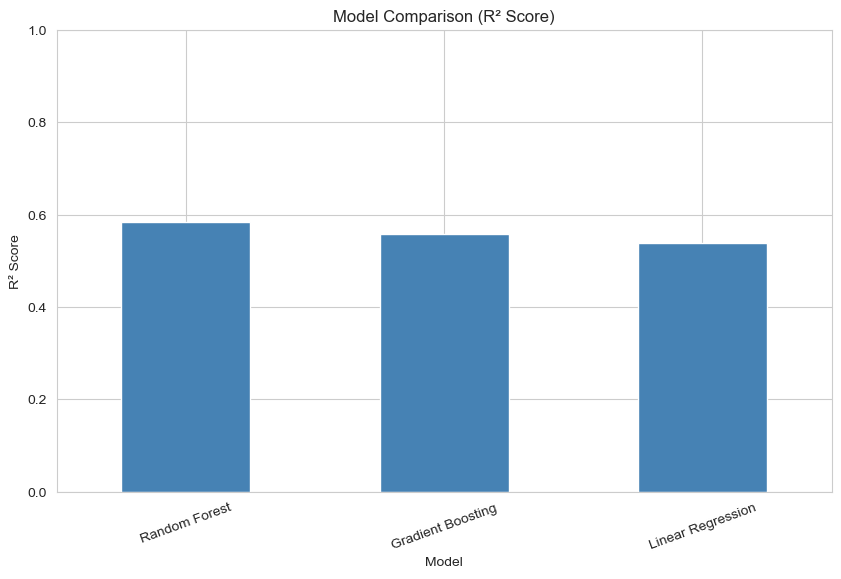

Best model: Random Forest | R2: 0.585


In [33]:
results_df.set_index("Model")["R2"].plot(kind="bar", color="steelblue", ylim=(0, 1))
plt.title("Model Comparison (R² Score)")
plt.ylabel("R² Score")
plt.xticks(rotation=20)
plt.show()

best_name = results_df.loc[0, "Model"]
print("Best model:", best_name, "| R2:", round(results_df.loc[0, "R2"], 3))

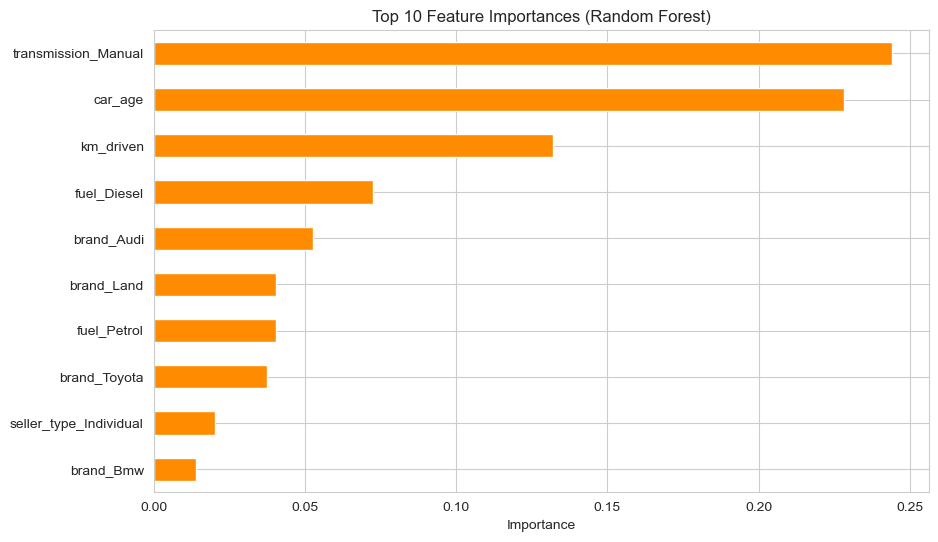

In [35]:
best_model = models[best_name]

# Tree models give feature_importances_; Linear Regression uses coefficient size
if hasattr(best_model, "feature_importances_"):
    importance = pd.Series(best_model.feature_importances_, index=X.columns)
else:
    importance = pd.Series(np.abs(best_model.coef_), index=X.columns)

importance.sort_values().tail(10).plot(kind="barh", color="darkorange")
plt.title(f"Top 10 Feature Importances ({best_name})")
plt.xlabel("Importance")
plt.show()